In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = sns.load_dataset('iris')

<Axes: xlabel='sepal_length', ylabel='Density'>

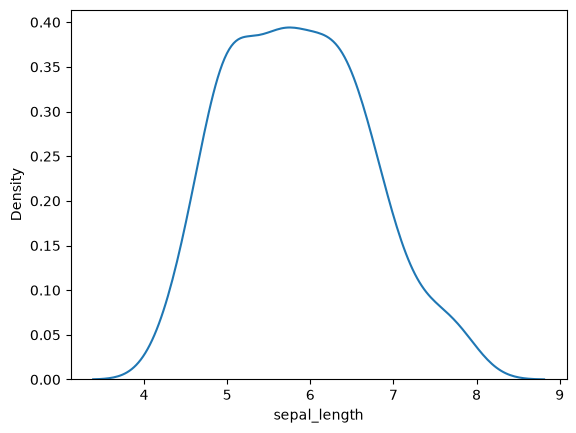

In [3]:
sns.kdeplot(df['sepal_length'])

In [17]:
# sepal length normally distributed lag raha hai
# pataa kaise lgega?
# q-q plot karke dekh lete hai


# sort karte hai "sepal length" ke data ko

temp = sorted(df['sepal_length'].to_list())
print(type(temp))


# sort ke baad ?
# quantile nikalni hai

y_quant = []

for i in range(1,101):
    y_quant.append(np.percentile(temp,i))

# done, percentiles bhi calculate karli

<class 'list'>


In [12]:
# ab data generate karte hai jo normally distributed hai


samples = np.random.normal(loc=0, scale=1, size=1000)
# mean = 0
# std = 1

In [18]:
# ab isko sort karnege + percntile nikalenge

samples = sorted(samples)
type(samples)
x_quant = []

for i in range(1,101):
    x_quant.append(np.percentile(samples, i))


<Axes: >

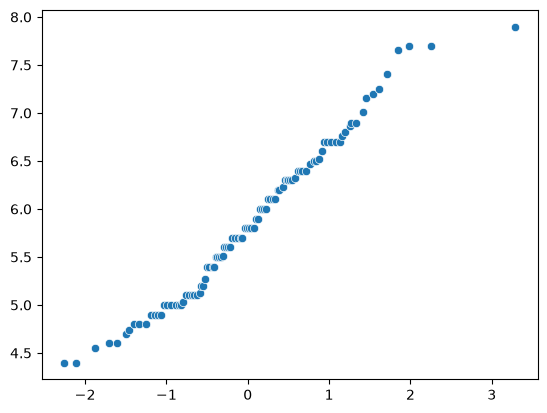

In [19]:
# scatter plot kar lete hai

sns.scatterplot(x=x_quant, y=y_quant)

In [ ]:
# so this is q-q plot
# not perfectly on a line 
# but still around the line

* there is a library that can do sorting and calcualting percentile in itself. and automaticaly takes a theoretical distribtion itself also.
* Using statstool

In [21]:
pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.3 MB 3.3 MB/s eta 0:00:04
   ----- ---------------------------------- 1.6/11.3 MB 2.9 MB/s eta 0:00:04
   ------- -------------------------------- 2.1/11.3 MB 2.7 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/11.3 MB 2.8 MB/s eta 0:00:03
   ------------ --------------------------- 3.4/11.3 MB 3.0 MB/s eta 0:00:03
   --------------- ------------------------ 4.5/11.3 MB 3.1 MB/s eta 0:00:03
   ------------------- -------------------- 5.5/11.3 MB 3.3 MB/s eta 0:00:02
   ----------------------- ---------------- 6.6/11.3 MB 3.5 MB/s eta 0:00:02
   -------------------------- ------------- 7.6/11.3 MB 3.6 MB/s eta 0:00:02
   ------------------------------ --------- 8.7/11.3 MB 3.7 MB/s eta 0:00:01
   ---------------------------------- ----- 9.7/11.3 MB 3.8 MB/s eta 0:00:01
   ----------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
#using statstool

import statsmodels.api as sm


#the theoretical distribution defaults to the standard normal distribution

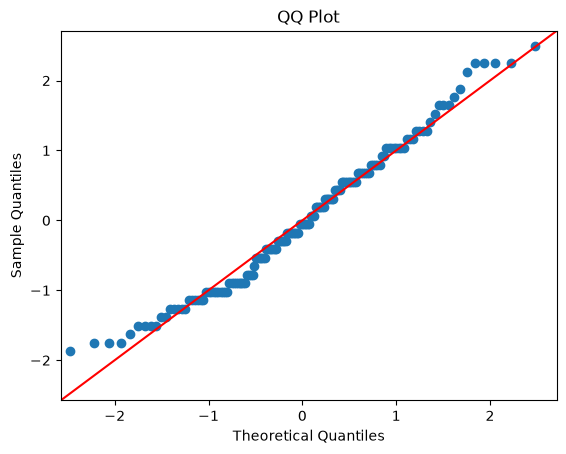

In [24]:
# creating q-q plot of 2 distributions

fig = sm.qqplot(df['sepal_length'], line='45', fit= True)

plt.title("QQ Plot")
plt.xlabel("Theoretical Quantiles")
plt.ylabel('Sample Quantiles')

plt.show()

##### lets do it for 
* sample dist Vs Uniform dist.

In [ ]:
x = np.random.uniform(low=0, high=1, size=1000)

(array([103.,  86., 115.,  95.,  91.,  96.,  95., 109., 100., 110.]),
 array([6.11845525e-04, 1.00530060e-01, 2.00448275e-01, 3.00366489e-01,
        4.00284704e-01, 5.00202918e-01, 6.00121133e-01, 7.00039348e-01,
        7.99957562e-01, 8.99875777e-01, 9.99793991e-01]),
 <BarContainer object of 10 artists>)

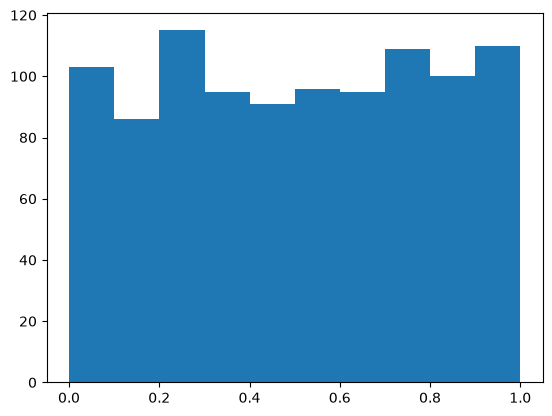

In [27]:
plt.hist(x)

In [29]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
import scipy.stats as stats

In [31]:
# fitting a uniform dist to the data

params = stats.uniform.fit(x)
# returns (loc, scale)

dist = stats.uniform(loc=params[0], scale=params[1])

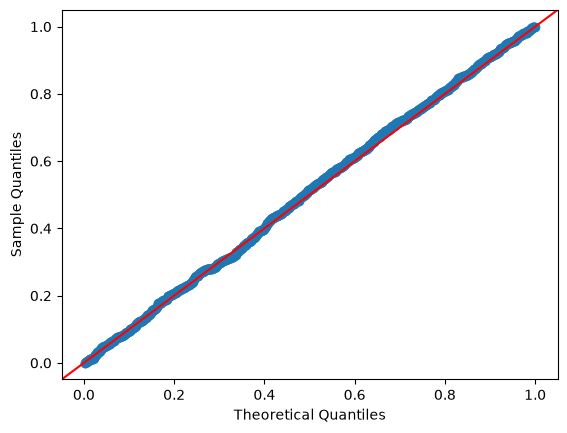

In [32]:
fig = sm.qqplot(x, dist=dist, line='45')

##### Checking Pareto dist. or not
* using log log plot

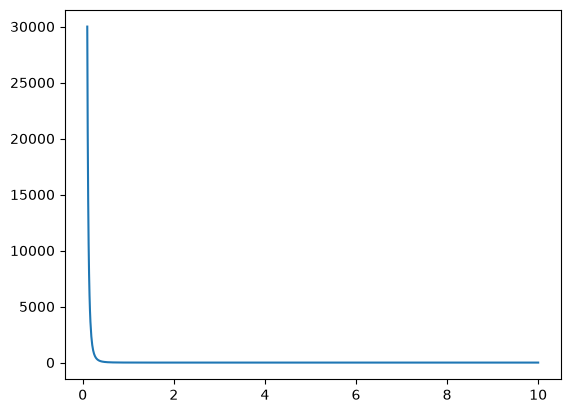

In [35]:
# define the parameters of pareto distribution

alpha = 3
xm = 1


# create an array of x values
x = np.linspace(0.1, 10, 1000)

y = (alpha * (xm)** alpha) / (x)** (alpha+1)

plt.plot(x,y)

#since alpha is higher, we got a parallel line to y-axis.

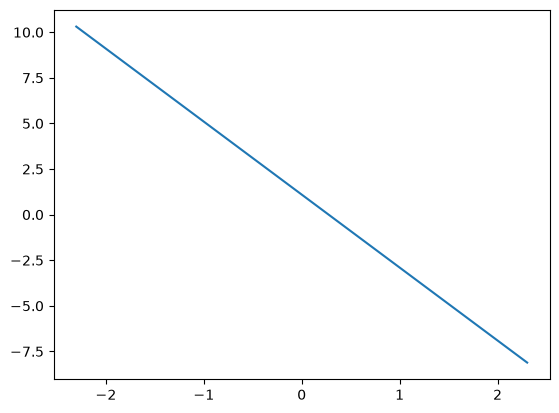

In [36]:
plt.plot(np.log(x), np.log(y))

#so its a perfect line and we got to know that choosen distribution is pareto distribution.

##### Using Q-Q plot
* Sample dist VS pareto dist

In [37]:
# parameters
alpha = 2
xm = 1


# generate a set of random data from pareto distribution
x = stats.pareto.rvs(b=alpha, scale=xm, size=1000)

(array([976.,  17.,   5.,   1.,   0.,   0.,   0.,   0.,   0.,   1.]),
 array([ 1.00014369,  5.75240772, 10.50467174, 15.25693577, 20.0091998 ,
        24.76146383, 29.51372786, 34.26599189, 39.01825592, 43.77051995,
        48.52278398]),
 <BarContainer object of 10 artists>)

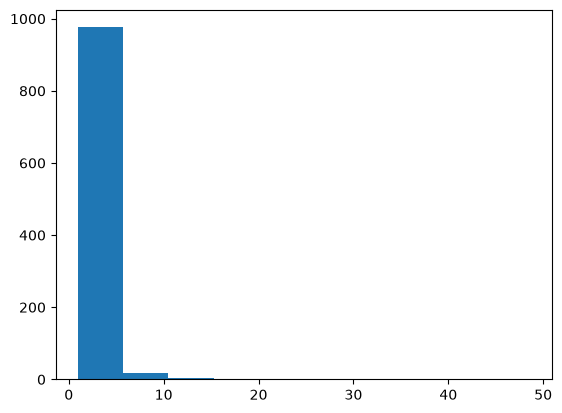

In [38]:
plt.hist(x)

In [39]:
# most of the data is in 20% of X.

In [40]:
#fit a pareto dist. to the data
params = stats.pareto.fit(x, floc = 0)

# create a pareto distribution object  with the fitted parameters
dist = stats.pareto(b=params[0], scale = params[2])

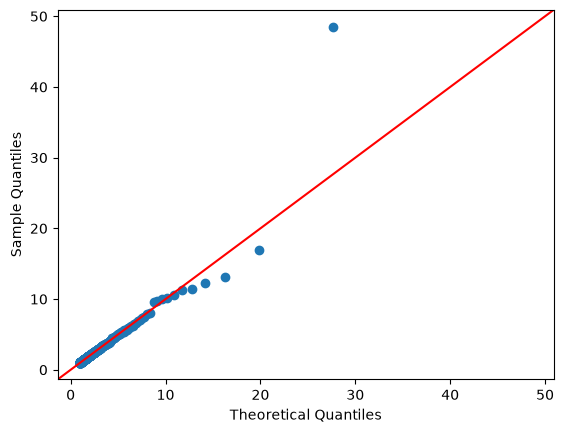

In [41]:
# create a q-q plot of the data using the pareto distribution

fig = sm.qqplot(x, dist, line='45')

In [42]:
# most of the data is lying on the straight line so it can be said that
# choosen sample is following pareto distribution.